In [30]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub


In [31]:
path = kagglehub.competition_download("binaryclassificationwithabankchurndataset")
print(path)
print(os.listdir(path))


/Users/muhammadaminesaev/.cache/kagglehub/competitions/binaryclassificationwithabankchurndataset
['test.csv', 'train.csv', 'sample_submission.csv']


In [32]:
train = pd.read_csv(os.path.join(path, "train.csv"))
test = pd.read_csv(os.path.join(path, "test.csv"))
sample_sub = pd.read_csv(os.path.join(path, "sample_submission.csv"))

display(train.head())
display(test.head())



,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,15000,15732563.0,Hs?,707.0,Germany,Male,21.0,4.0,114513.66,2.0,1.0,0.0,176692.87
1,15001,15727041.0,Ma,678.0,Germany,Male,33.0,5.0,142510.50,1.0,0.0,0.0,52820.13
2,15002,15753679.0,K?,636.0,Spain,Male,45.0,9.0,0.00,2.0,1.0,1.0,125062.02
3,15003,15581554.0,H?,697.0,Spain,Male,46.0,8.0,0.00,2.0,1.0,0.0,131647.41
4,15004,15773723.0,Bellucci,553.0,Spain,Male,31.0,2.0,0.00,2.0,1.0,0.0,58814.41


In [33]:
print("train:", train.shape)
print("test:", test.shape)
#print()
print(train.isnull().sum())


train: (15000, 14)
test: (10000, 13)
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Exited
0.0    12023
1.0     2977
Name: count, dtype: int64
Exited
0.0    0.801533
1.0    0.198467
Name: proportion, dtype: float64


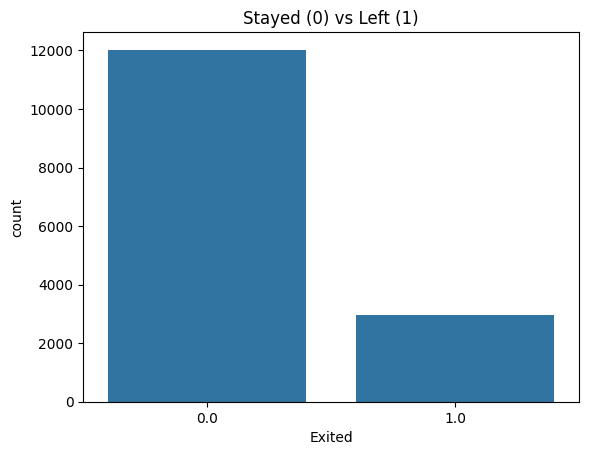

In [34]:
print(train["Exited"].value_counts())
print(train["Exited"].value_counts(normalize=True))

sns.countplot(x="Exited", data=train)
plt.title("Stayed (0) vs Left (1)")
plt.show()


In [35]:
pd.DataFrame({
    "dtype": train.dtypes,
    "n_unique": train.nunique()
})


,dtype,n_unique
id,int64,15000
CustomerId,float64,6306
Surname,object,758
CreditScore,float64,378
Geography,object,3
Gender,object,2
Age,float64,55
Tenure,float64,11
Balance,float64,3328
NumOfProducts,float64,5


In [36]:
print(train["NumOfProducts"].value_counts().sort_index())
print()
print("Customers with Balance == 0:", (train["Balance"] == 0).mean())


NumOfProducts
1.0    6379
2.0    8406
3.0     194
4.0      20
5.0       1
Name: count, dtype: int64

Customers with Balance == 0: 0.6534666666666666


In [37]:
for col in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard"]:
    summary = train.groupby(col)["Exited"].agg(["mean", "count"])
    summary.columns = ["churn_rate", "customers"]
    print(summary.round(3))
    print()


           churn_rate  customers
Geography                       
France          0.154       9040
Germany         0.406       2680
Spain           0.152       3280

        churn_rate  customers
Gender                       
Female       0.276       6522
Male         0.139       8478

               churn_rate  customers
NumOfProducts                       
1.0                 0.380       6379
2.0                 0.042       8406
3.0                 0.954        194
4.0                 0.850         20
5.0                 1.000          1

                churn_rate  customers
IsActiveMember                       
0.0                  0.273       7560
1.0                  0.123       7440

           churn_rate  customers
HasCrCard                       
0.0             0.206       3313
1.0             0.196      11687



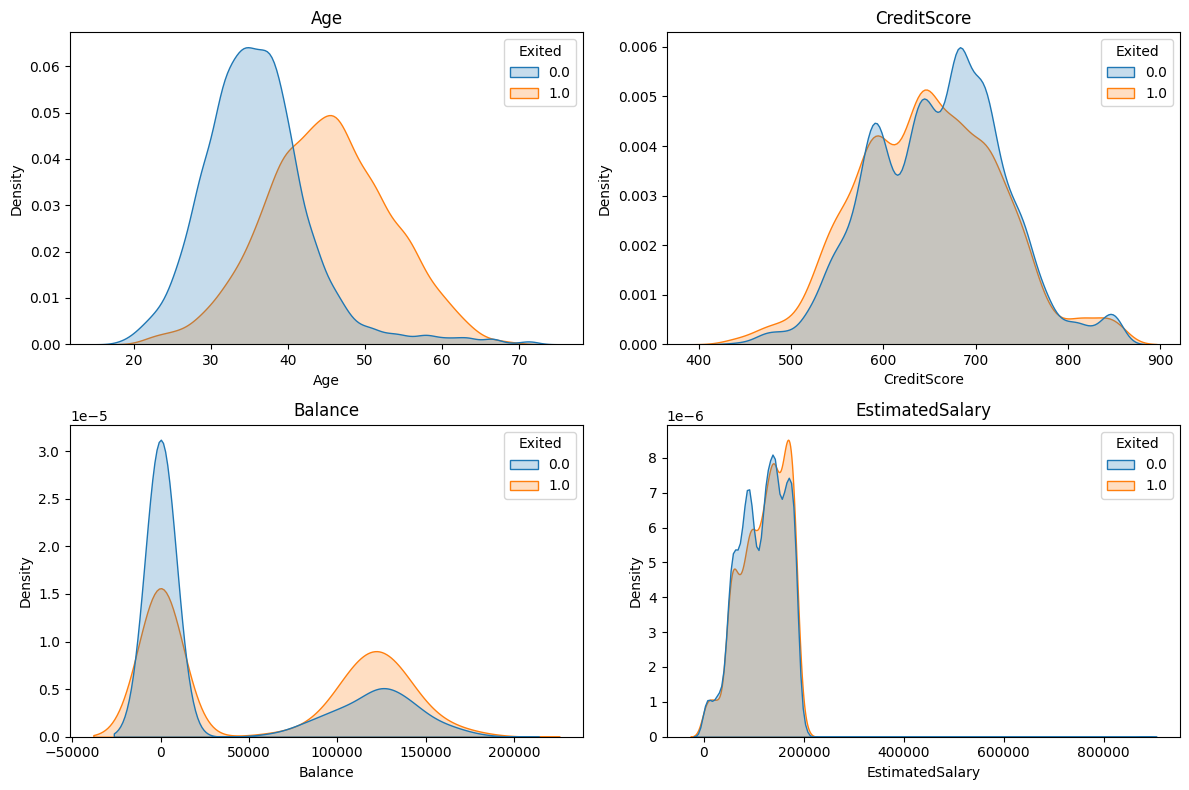

In [38]:
num_cols = ["Age", "CreditScore", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.kdeplot(data=train, x=col, hue="Exited", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [39]:
drop_cols = ["id", "CustomerId", "Surname"]

X = train.drop(columns=drop_cols + ["Exited"])
y = train["Exited"].astype(int)
X_test = test.drop(columns=drop_cols)

X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=["Geography", "Gender"], drop_first=True, dtype=int)

print(X.shape, X_test.shape)
X.head()


(15000, 11) (10000, 11)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,567.0,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0,0,1
1,628.0,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,0,0,0
2,635.0,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0,0,0
3,681.0,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0,0,1
4,587.0,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0,0,0


In [40]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(logreg, X, y, cv=cv, scoring="roc_auc")

print("AUC per fold:", scores.round(4))
print("Mean AUC:", scores.mean().round(4))


AUC per fold: [0.892  0.8799 0.8836 0.8767 0.8824]
Mean AUC: 0.8829


In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(random_state=42)
scores = cross_val_score(hgb, X, y, cv=cv, scoring="roc_auc")

print("AUC per fold:", scores.round(4))
print("Mean AUC:", scores.mean().round(4))


AUC per fold: [0.9349 0.9282 0.9302 0.9298 0.9324]
Mean AUC: 0.9311


In [43]:
hgb.fit(X, y)
pred = hgb.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({"id": test["id"], "Exited": pred})
submission.to_csv("submission.csv", index=False)

print(submission.shape)
submission.head()


(10000, 2)


,id,Exited
0,15000,0.032648
1,15001,0.140270
2,15002,0.022170
3,15003,0.080906
4,15004,0.008198
